<a href="https://colab.research.google.com/github/zegavibiano22-tech/WiFi-CSI-CrossDomain-Sensing/blob/main/notebooks/01_eda_bvp_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Variabel dalam file .mat: ['velocity_spectrum_ro']
Bentuk matriks (Shape) dari 'velocity_spectrum_ro': (20, 20, 20)


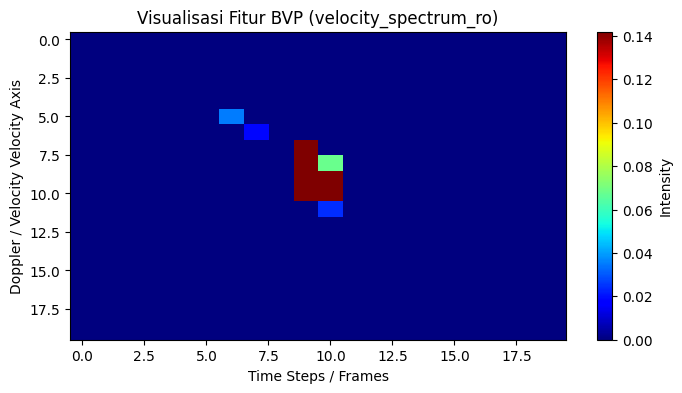

In [ ]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

# Load file sampel .mat yang barusan kamu upload
# Sesuaikan nama filenya jika beda
file_name = 'user1-1-1-1-1-1-1e-07-100-20-100000-L0.mat'

data = sio.loadmat(file_name)

# 1. Cek variabel (keys) apa saja yang ada di dalam file .mat
keys = [k for k in data.keys() if not k.startswith('__')]
print("Variabel dalam file .mat:", keys)

# 2. Ambil matriks data (biasanya key utamanya bernama 'bvp' atau 'csi')
key_utama = keys[0]
matriks = data[key_utama]
print(f"Bentuk matriks (Shape) dari '{key_utama}':", matriks.shape)

# 3. Visualisasi data BVP
plt.figure(figsize=(8, 4))
if matriks.ndim == 3:
    plt.imshow(matriks[:, :, 0], aspect='auto', cmap='jet')
elif matriks.ndim == 2:
    plt.imshow(matriks, aspect='auto', cmap='jet')
else:
    plt.plot(matriks.flatten())

plt.title(f"Visualisasi Fitur BVP ({key_utama})")
plt.colorbar(label='Intensity')
plt.xlabel("Time Steps / Frames")
plt.ylabel("Doppler / Velocity Velocity Axis")
plt.show()

**Inspeksi & Visualisasi Data**

Fungsi: Mengunduh dan membaca struktur file .mat dari dataset Widar 3.0.

Tujuan: Memastikan variabel utama (velocity_spectrum_ro), mengecek dimensi data ($(20, 20, 20)$), serta menampilkan grafik pola BVP (Body Velocity Profile) untuk memastikan sinyal tidak rusak.

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import re

def parse_filename(filename):
    # Mengambil ID gesture dan environment dari nama file Widar 3.0
    parts = filename.split('-')

    # Ekstraksi label gesture dan environment
    user_id = int(re.search(r'\d+', parts[0]).group())
    gesture_label = int(parts[1]) - 1     # Class target (misal: 0-5)
    env_label = int(parts[2]) - 1         # Domain target (misal: 0-2)

    return gesture_label, env_label

# Cek parse nama file sampel
sample_name = 'user1-1-1-1-1-1e-07-100-20-100000-L0.mat'
g_label, e_label = parse_filename(sample_name)

# Konversi matriks BVP ke PyTorch Tensor
tensor_bvp = torch.tensor(matriks, dtype=torch.float32)

print(f"File: {sample_name}")
print(f"Parsed Gesture Label (Y) : {g_label}")
print(f"Parsed Domain/Env (D)    : {e_label}")
print(f"Shape Tensor PyTorch     : {tensor_bvp.shape}")

**Parser Label & Konversi Tensor**

Fungsi: Membedah string nama file (contoh: user1-1-1-1-1...) menjadi informasi berformat angka.   

Tujuan: Mengekstrak label target gerakan/gestur ($Y$) dan label lingkungan/domain ($D$), lalu mengubah matriks BVP dari format NumPy menjadi Tensor PyTorch agar bisa diproses oleh Neural Network.

In [ ]:
import os
import glob
import torch
from torch.utils.data import Dataset, DataLoader
import scipy.io as sio

class WidarBVPDataset(Dataset):
    def __init__(self, file_paths):
        self.file_paths = file_paths

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        file_path = self.file_paths[idx]
        filename = os.path.basename(file_path)

        # Load matriks BVP
        data = sio.loadmat(file_path)
        matriks = data['velocity_spectrum_ro']

        # Parse label gesture (Y) & domain (D)
        parts = filename.split('-')
        gesture_label = int(parts[1]) - 1
        env_label = int(parts[2]) - 1

        # Convert ke PyTorch Tensor
        # Format Tensor: (Channel=1, Time=20, Height=20, Width=20) untuk input CNN
        tensor_bvp = torch.tensor(matriks, dtype=torch.float32).unsqueeze(0)

        return tensor_bvp, torch.tensor(gesture_label, dtype=torch.long), torch.tensor(env_label, dtype=torch.long)

# Testing DatasetLoader dengan file sampel yang ada
sample_files = glob.glob('*.mat')
dataset = WidarBVPDataset(sample_files)
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

# Cek 1 batch data
for bvp_batch, y_batch, d_batch in dataloader:
    print("Batch BVP Shape     :", bvp_batch.shape)  # Expect: [1, 1, 20, 20, 20]
    print("Batch Gesture Label :", y_batch)
    print("Batch Domain Label  :", d_batch)
    break

Batch BVP Shape     : torch.Size([1, 1, 20, 20, 20])
Batch Gesture Label : tensor([0])
Batch Domain Label  : tensor([0])


**Class WidarBVPDataset (PyTorch DataLoader)**

Fungsi: Menggabungkan fungsi pembacaan data dan ekstraksi label ke dalam satu struktur class PyTorch.   

Tujuan: Otomatisasi pemrosesan dataset dalam bentuk batch ([batch_size, channels, time, height, width]) agar siap diumpankan secara efisien ke model Baseline (1D-CNN+LSTM) maupun model Proposed (DANN) saat tahap training.